In [1]:
import ollama
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

from itertools import product, combinations
from pathlib import Path

client = ollama.Client(
    host="http://localhost:11434",
    timeout=600
)

print(client.list())

models=[Model(model='llama3.2:3b', modified_at=datetime.datetime(2026, 10, 20, 20, 16, 56, 963913, tzinfo=TzInfo(18000)), digest='a80c4f17acd55265feec403c7aef86be0c25983ab279d83f3bcd3abbcb5b8b72', size=2019393189, details=ModelDetails(parent_model='', format='gguf', family='llama', families=['llama'], parameter_size='3.2B', quantization_level='Q4_K_M')), Model(model='qwen2.5:latest', modified_at=datetime.datetime(2026, 10, 5, 23, 51, 36, 33783, tzinfo=TzInfo(18000)), digest='845dbda0ea48ed749caafd9e6037047aa19acfcfd82e704d7ca97d631a0b697e', size=4683087332, details=ModelDetails(parent_model='', format='gguf', family='qwen2', families=['qwen2'], parameter_size='7.6B', quantization_level='Q4_K_M')), Model(model='llama3.2:latest', modified_at=datetime.datetime(2026, 10, 5, 23, 30, 32, 502980, tzinfo=TzInfo(18000)), digest='a80c4f17acd55265feec403c7aef86be0c25983ab279d83f3bcd3abbcb5b8b72', size=2019393189, details=ModelDetails(parent_model='', format='gguf', family='llama', families=['llam

In [2]:
PROMPT = """
Answer the following using only one JSON object.
Do not use Markdown, code fences, or any text outside the JSON.

Use exactly these four keys:
"capital", "planet", "symbol", "explanation"

Give all values as strings.

capital: What is the capital of Pakistan?
planet: Which planet is known as the Red Planet?
symbol: What is the chemical symbol for gold?
explanation: In one sentence, explain why Earth has seasons.
"""

MODELS = ["llama3.2:3b", "qwen2.5:3b"]
TEMPERATURES = [0.0, 0.3, 0.7, 1.0]
TOP_K_VALUES = [10, 20, 50, 100]
TOP_P_VALUES = [0.5, 0.7, 0.9, 1.0]
SEEDS = [42, 123, 456]

print("Total responses:",
      len(MODELS) * len(TEMPERATURES)
      * len(TOP_K_VALUES) * len(TOP_P_VALUES)
      * len(SEEDS))

Total responses: 384


In [3]:
test = client.chat(
    model=MODELS[0],
    messages=[{"role": "user", "content": PROMPT}],
    options={
        "temperature": 0.0,
        "top_k": 10,
        "top_p": 0.5,
        "seed": 42,
        "num_predict": 200,
        "num_ctx": 2048
    }
)

print(test.message.content)

{"capital": "Islamabad", "planet": "Mars", "symbol": "Au", "explanation": "Earth has seasons due to its tilt on its axis as it orbits the sun."}


In [4]:
output_file = Path("decoding_results.csv")

columns = [
    "model", "temperature", "top_k", "top_p",
    "seed", "response", "done_reason"
]

if output_file.exists():
    existing = pd.read_csv(output_file)
    completed = set(
        existing[
            ["model", "temperature", "top_k", "top_p", "seed"]
        ].itertuples(index=False, name=None)
    )
else:
    completed = set()

experiments = list(product(
    MODELS, TEMPERATURES, TOP_K_VALUES, TOP_P_VALUES, SEEDS
))

for number, settings in enumerate(experiments, start=1):
    model, temperature, top_k, top_p, seed = settings

    if settings in completed:
        continue

    result = client.chat(
        model=model,
        messages=[{"role": "user", "content": PROMPT}],
        options={
            "temperature": temperature,
            "top_k": top_k,
            "top_p": top_p,
            "seed": seed,
            "num_predict": 200,
            "num_ctx": 2048
        }
    )

    row = {
        "model": model,
        "temperature": temperature,
        "top_k": top_k,
        "top_p": top_p,
        "seed": seed,
        "response": result.message.content,
        "done_reason": result.done_reason
    }

    pd.DataFrame([row], columns=columns).to_csv(
        output_file,
        mode="a",
        header=not output_file.exists(),
        index=False
    )

    completed.add(settings)
    print(f"{number}/384 completed: {settings}")

print("Experiment finished.")

1/384 completed: ('llama3.2:3b', 0.0, 10, 0.5, 42)
2/384 completed: ('llama3.2:3b', 0.0, 10, 0.5, 123)
3/384 completed: ('llama3.2:3b', 0.0, 10, 0.5, 456)
4/384 completed: ('llama3.2:3b', 0.0, 10, 0.7, 42)
5/384 completed: ('llama3.2:3b', 0.0, 10, 0.7, 123)
6/384 completed: ('llama3.2:3b', 0.0, 10, 0.7, 456)
7/384 completed: ('llama3.2:3b', 0.0, 10, 0.9, 42)
8/384 completed: ('llama3.2:3b', 0.0, 10, 0.9, 123)
9/384 completed: ('llama3.2:3b', 0.0, 10, 0.9, 456)
10/384 completed: ('llama3.2:3b', 0.0, 10, 1.0, 42)
11/384 completed: ('llama3.2:3b', 0.0, 10, 1.0, 123)
12/384 completed: ('llama3.2:3b', 0.0, 10, 1.0, 456)
13/384 completed: ('llama3.2:3b', 0.0, 20, 0.5, 42)
14/384 completed: ('llama3.2:3b', 0.0, 20, 0.5, 123)
15/384 completed: ('llama3.2:3b', 0.0, 20, 0.5, 456)
16/384 completed: ('llama3.2:3b', 0.0, 20, 0.7, 42)
17/384 completed: ('llama3.2:3b', 0.0, 20, 0.7, 123)
18/384 completed: ('llama3.2:3b', 0.0, 20, 0.7, 456)
19/384 completed: ('llama3.2:3b', 0.0, 20, 0.9, 42)
20/384 co

In [5]:
df = pd.read_csv("decoding_results.csv")

print("Total responses:", len(df))
print("\nResponses per model:")
print(df.groupby("model").size())

print("\nCompletion reasons:")
print(df["done_reason"].value_counts(dropna=False))

df.head()

Total responses: 384

Responses per model:
model
llama3.2:3b    192
qwen2.5:3b     192
dtype: int64

Completion reasons:
done_reason
stop    384
Name: count, dtype: int64


,model,temperature,top_k,top_p,seed,response,done_reason
0,llama3.2:3b,0.0,10,0.5,42,"{""capital"": ""Islamabad"", ""planet"": ""Mars"", ""sy...",stop
1,llama3.2:3b,0.0,10,0.5,123,"{""capital"": ""Islamabad"", ""planet"": ""Mars"", ""sy...",stop
2,llama3.2:3b,0.0,10,0.5,456,"{""capital"": ""Islamabad"", ""planet"": ""Mars"", ""sy...",stop
3,llama3.2:3b,0.0,10,0.7,42,"{""capital"": ""Islamabad"", ""planet"": ""Mars"", ""sy...",stop
4,llama3.2:3b,0.0,10,0.7,123,"{""capital"": ""Islamabad"", ""planet"": ""Mars"", ""sy...",stop


In [6]:
def evaluate(text):
    try:
        answer = json.loads(text)
    except (json.JSONDecodeError, TypeError):
        return pd.Series({
            "structure_ok": 0,
            "fact_accuracy": np.nan
        })

    if not isinstance(answer, dict):
        return pd.Series({
            "structure_ok": 0,
            "fact_accuracy": np.nan
        })

    required = {"capital", "planet", "symbol", "explanation"}

    structure_ok = (
        set(answer) == required
        and all(isinstance(v, str) for v in answer.values())
    )

    correct = [
        str(answer.get("capital", "")).strip().casefold()
        == "islamabad",

        str(answer.get("planet", "")).strip().casefold()
        == "mars",

        str(answer.get("symbol", "")).strip()
        == "Au"
    ]

    return pd.Series({
        "structure_ok": int(structure_ok),
        "fact_accuracy": np.mean(correct)
    })

scores = df["response"].apply(evaluate)
df = pd.concat([df, scores], axis=1)

df.to_csv("scored_results.csv", index=False)

df[[
    "model", "temperature", "top_k", "top_p",
    "structure_ok", "fact_accuracy"
]].head()

,model,temperature,top_k,top_p,structure_ok,fact_accuracy
0,llama3.2:3b,0.0,10,0.5,1.0,1.0
1,llama3.2:3b,0.0,10,0.5,1.0,1.0
2,llama3.2:3b,0.0,10,0.5,1.0,1.0
3,llama3.2:3b,0.0,10,0.7,1.0,1.0
4,llama3.2:3b,0.0,10,0.7,1.0,1.0


In [7]:
group_columns = ["model", "temperature", "top_k", "top_p"]

def agreement(responses):
    texts = [str(text).strip() for text in responses]
    pairs = list(combinations(texts, 2))
    return np.mean([a == b for a, b in pairs])

summary = df.groupby(group_columns).agg(
    responses=("response", "size"),
    structure_rate=("structure_ok", "mean"),
    fact_accuracy=("fact_accuracy", "mean"),
    scored_responses=("fact_accuracy", "count")
).reset_index()

consistency = (
    df.groupby(group_columns)["response"]
    .apply(agreement)
    .rename("exact_agreement")
    .reset_index()
)

summary = summary.merge(consistency, on=group_columns)
summary.to_csv("parameter_summary.csv", index=False)

summary.head(10)

,model,temperature,top_k,top_p,responses,structure_rate,fact_accuracy,scored_responses,exact_agreement
0,llama3.2:3b,0.0,10,0.5,3,1.0,1.0,3,1.0
1,llama3.2:3b,0.0,10,0.7,3,1.0,1.0,3,1.0
2,llama3.2:3b,0.0,10,0.9,3,1.0,1.0,3,1.0
3,llama3.2:3b,0.0,10,1.0,3,1.0,1.0,3,1.0
4,llama3.2:3b,0.0,20,0.5,3,1.0,1.0,3,1.0
5,llama3.2:3b,0.0,20,0.7,3,1.0,1.0,3,1.0
6,llama3.2:3b,0.0,20,0.9,3,1.0,1.0,3,1.0
7,llama3.2:3b,0.0,20,1.0,3,1.0,1.0,3,1.0
8,llama3.2:3b,0.0,50,0.5,3,1.0,1.0,3,1.0
9,llama3.2:3b,0.0,50,0.7,3,1.0,1.0,3,1.0


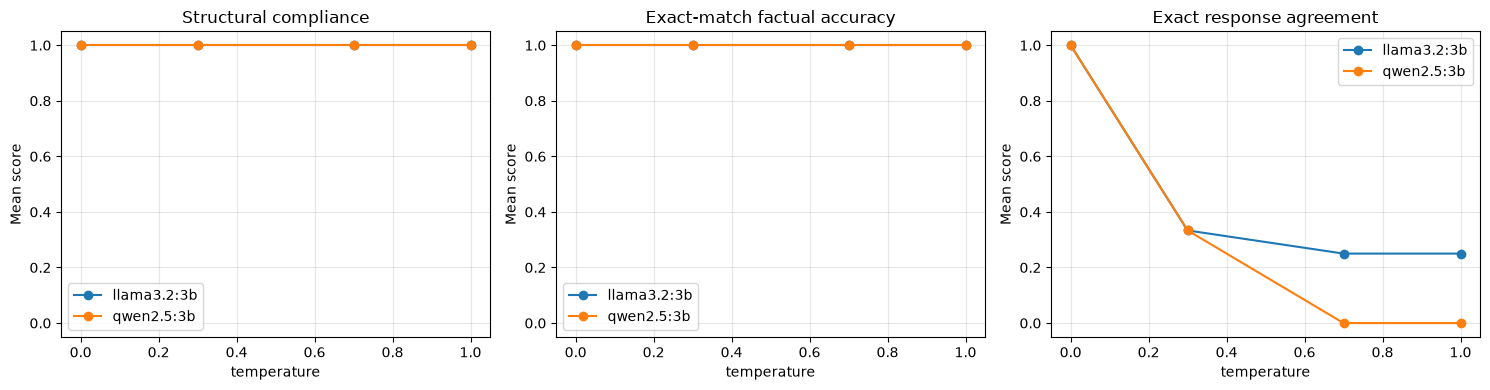

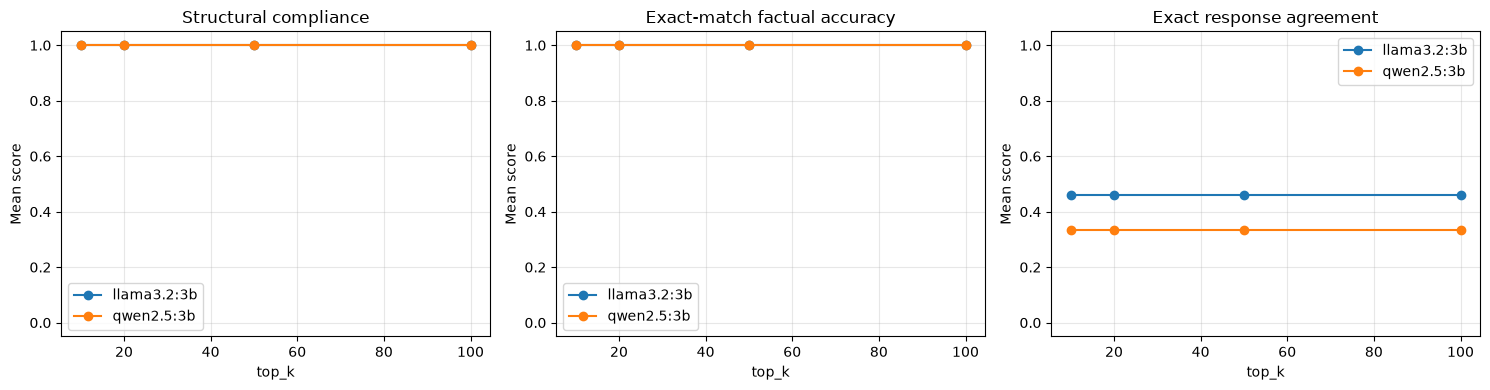

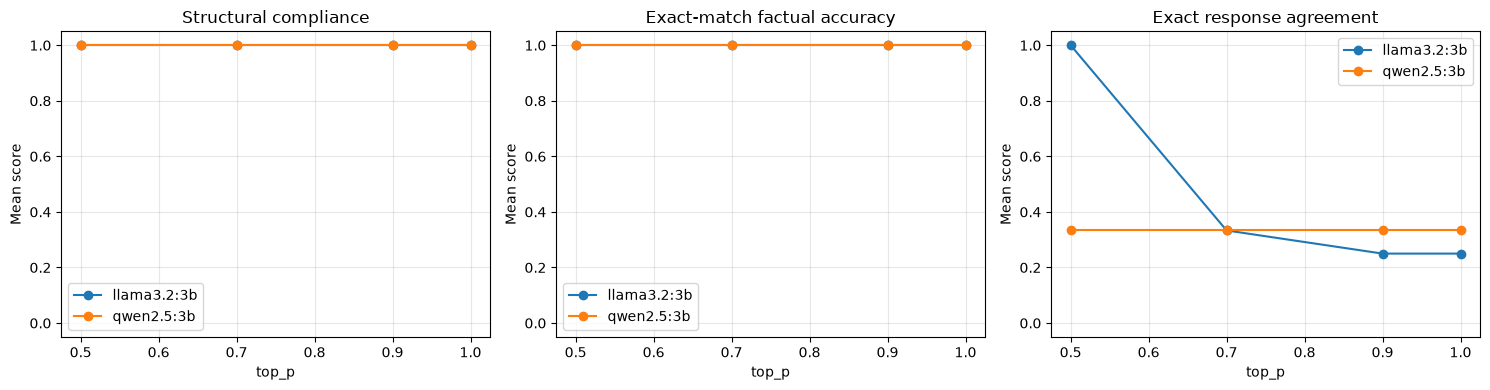

In [8]:
metrics = {
    "structure_rate": "Structural compliance",
    "fact_accuracy": "Exact-match factual accuracy",
    "exact_agreement": "Exact response agreement"
}

for parameter in ["temperature", "top_k", "top_p"]:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    for ax, (metric, title) in zip(axes, metrics.items()):
        for model in MODELS:
            values = (
                summary[summary["model"] == model]
                .groupby(parameter)[metric]
                .mean()
            )

            ax.plot(
                values.index, values.values,
                marker="o", label=model
            )

        ax.set_title(title)
        ax.set_xlabel(parameter)
        ax.set_ylabel("Mean score")
        ax.set_ylim(-0.05, 1.05)
        ax.grid(alpha=0.3)
        ax.legend()

    plt.tight_layout()
    plt.savefig(f"{parameter}_comparison.png", dpi=200)
    plt.show()

## Observations

The experiment compared Llama 3.2 and Qwen 2.5 using one fixed prompt. Each model was tested with 64 combinations of decoding parameters, using three seeds for each combination.

### Factual Accuracy and Structural Compliance

Both models scored 1.0 on the automated factual accuracy and structural compliance checks across all tested settings.

The structural check confirmed that each response included the four required JSON fields with string values. The factual accuracy check assessed only the answers Islamabad, Mars, and Au. Factual accuracy was evaluated only for the three short-answer questions; the seasons explanation was not assessed.

### Effect of Temperature

At a temperature of 0.0, both models achieved an exact response agreement score of 1.0. This means that the responses generated using the three seeds were identical within each parameter combination.

As temperature increased, the responses became less consistent in their wording. Llama 3.2 still showed some exact agreement at temperatures of 0.7 and 1.0, while Qwen 2.5 showed none at these temperatures.

These results suggest that higher temperatures increased variation in the responses without affecting the factual accuracy or structural compliance measured by the automated checks.

### Effect of Top K

Changing Top K from 10 to 100 produced no visible difference in the averaged metrics for this prompt. Overall, Llama 3.2 had higher average exact response agreement than Qwen 2.5.

### Effect of Top P

Llama 3.2 produced the most consistent responses at a Top P value of 0.5. Its exact response agreement decreased as Top P increased. In comparison, Qwen 2.5 showed approximately the same average agreement across the tested Top P values.

Both models continued to achieve full scores on the automated factual accuracy and structural compliance checks.

## Conclusion

For this prompt, temperature clearly influenced how consistently the models repeated their responses. A temperature of 0.0 produced the most repeatable results, while higher temperatures led to more variation in wording.

Both models performed equally well on the three short factual questions and the automated JSON structure check. However, Llama 3.2 generally produced more repeatable responses across the tested settings.

Based on these results, a temperature of 0.0 is a suitable choice when identical responses are the main priority. Higher temperatures may be useful when varied wording is preferred, although this experiment does not show whether that variation makes the responses more creative or useful.

## Limitations

* The experiment used only one prompt and three seeds for each parameter combination.
* The factual questions were relatively simple.
* The automated factual accuracy check assessed only three short answers.
* The seasons explanation was not assessed for factual accuracy.
* A response with different wording is not necessarily incorrect.
* The graphs show averages across the other parameter settings, which may hide differences between individual combinations.
* These findings apply to the tested prompt and settings and should not be generalized to all prompts or models.

C:\Users\SH10
